In [36]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [37]:
df = pd.read_csv("/content/HeartDiseaseTrain-Test.csv")

In [38]:
df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholestoral,fasting_blood_sugar,rest_ecg,Max_heart_rate,exercise_induced_angina,oldpeak,slope,vessels_colored_by_flourosopy,thalassemia,target
0,52,Male,Typical angina,125,212,Lower than 120 mg/ml,ST-T wave abnormality,168,No,1.0,Downsloping,Two,Reversable Defect,0
1,53,Male,Typical angina,140,203,Greater than 120 mg/ml,Normal,155,Yes,3.1,Upsloping,Zero,Reversable Defect,0
2,70,Male,Typical angina,145,174,Lower than 120 mg/ml,ST-T wave abnormality,125,Yes,2.6,Upsloping,Zero,Reversable Defect,0
3,61,Male,Typical angina,148,203,Lower than 120 mg/ml,ST-T wave abnormality,161,No,0.0,Downsloping,One,Reversable Defect,0
4,62,Female,Typical angina,138,294,Greater than 120 mg/ml,ST-T wave abnormality,106,No,1.9,Flat,Three,Fixed Defect,0


In [39]:
df.tail()

,age,sex,chest_pain_type,resting_blood_pressure,cholestoral,fasting_blood_sugar,rest_ecg,Max_heart_rate,exercise_induced_angina,oldpeak,slope,vessels_colored_by_flourosopy,thalassemia,target
1020,59,Male,Atypical angina,140,221,Lower than 120 mg/ml,ST-T wave abnormality,164,Yes,0.0,Downsloping,Zero,Fixed Defect,1
1021,60,Male,Typical angina,125,258,Lower than 120 mg/ml,Normal,141,Yes,2.8,Flat,One,Reversable Defect,0
1022,47,Male,Typical angina,110,275,Lower than 120 mg/ml,Normal,118,Yes,1.0,Flat,One,Fixed Defect,0
1023,50,Female,Typical angina,110,254,Lower than 120 mg/ml,Normal,159,No,0.0,Downsloping,Zero,Fixed Defect,1
1024,54,Male,Typical angina,120,188,Lower than 120 mg/ml,ST-T wave abnormality,113,No,1.4,Flat,One,Reversable Defect,0


In [40]:
#Checking for null values
df.isnull().sum()

,0
age,0
sex,0
chest_pain_type,0
resting_blood_pressure,0
cholestoral,0
fasting_blood_sugar,0
rest_ecg,0
Max_heart_rate,0
exercise_induced_angina,0
oldpeak,0


In [41]:
#Checking for dupicate values
df.duplicated().sum()

np.int64(723)

In [42]:
#Treating duplicate values
df.drop_duplicates(inplace = True)

In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            302 non-null    int64  
 1   sex                            302 non-null    object 
 2   chest_pain_type                302 non-null    object 
 3   resting_blood_pressure         302 non-null    int64  
 4   cholestoral                    302 non-null    int64  
 5   fasting_blood_sugar            302 non-null    object 
 6   rest_ecg                       302 non-null    object 
 7   Max_heart_rate                 302 non-null    int64  
 8   exercise_induced_angina        302 non-null    object 
 9   oldpeak                        302 non-null    float64
 10  slope                          302 non-null    object 
 11  vessels_colored_by_flourosopy  302 non-null    object 
 12  thalassemia                    302 non-null    object 


<Axes: >

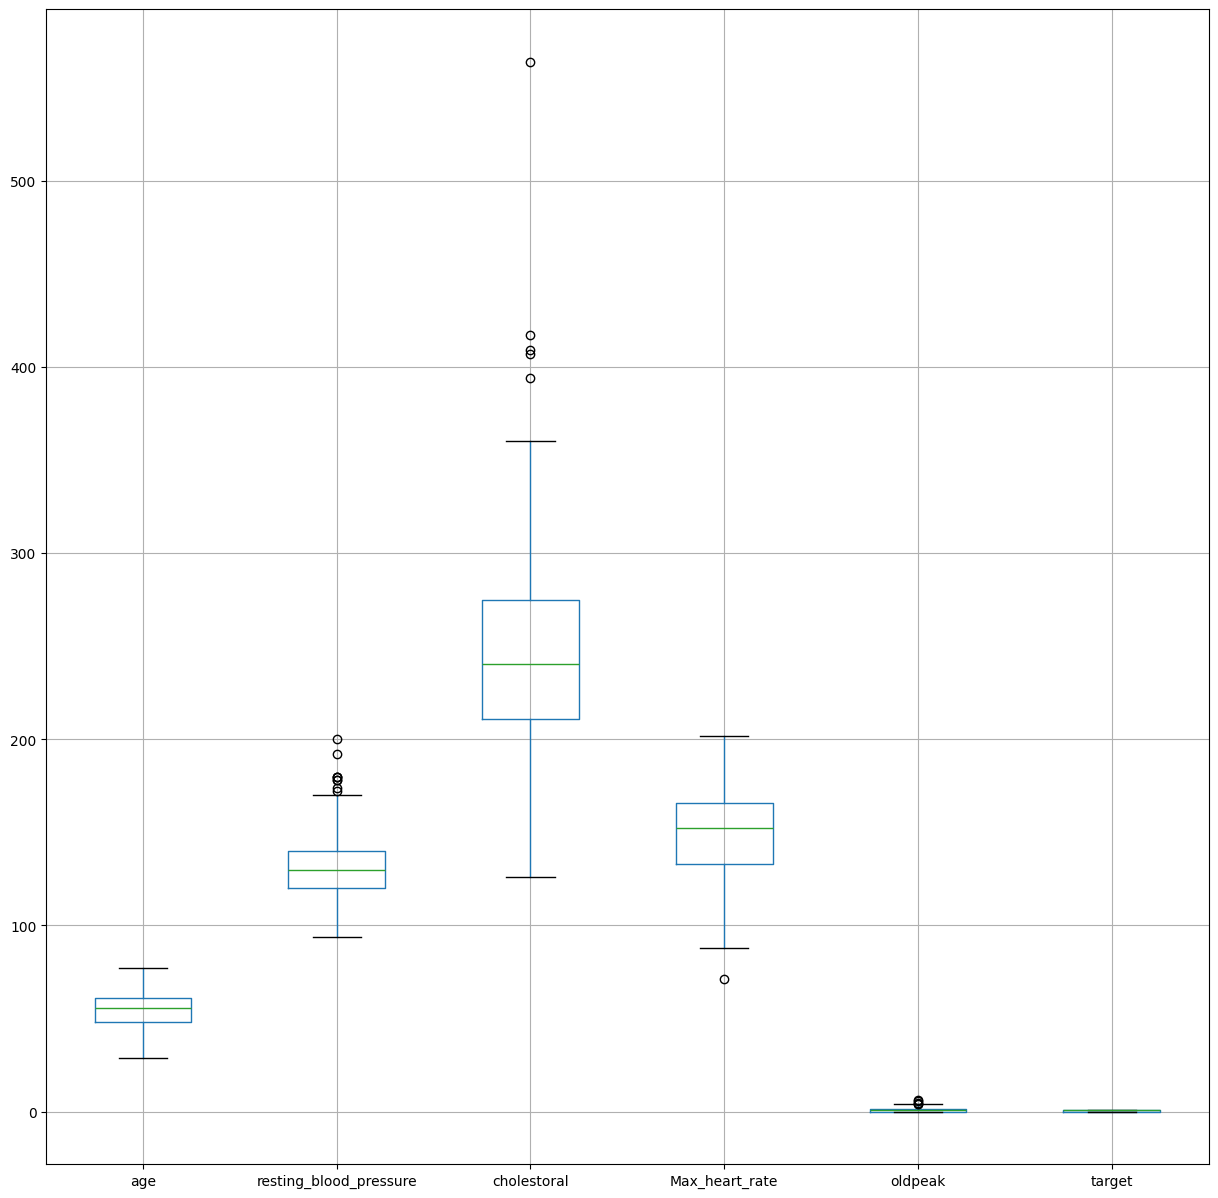

In [44]:
#Boxplot
df.select_dtypes(include='number').boxplot(figsize=(15,15))

In [45]:
#Outlier treatment
columns = [
    'resting_blood_pressure',
    'cholestoral',
    'Max_heart_rate',
    'oldpeak'
]

for i in columns:
  Q1 = df[i].quantile(0.25)
  Q3 = df[i].quantile(0.75)
  IQR = Q3-Q1
  lower_bound = Q1 - 1.5*IQR
  upper_bound = Q3 + 1.5*IQR

  df[i] = np.where(df[i] < lower_bound, lower_bound, df[i])
  df[i] = np.where(df[i] > upper_bound, upper_bound, df[i])

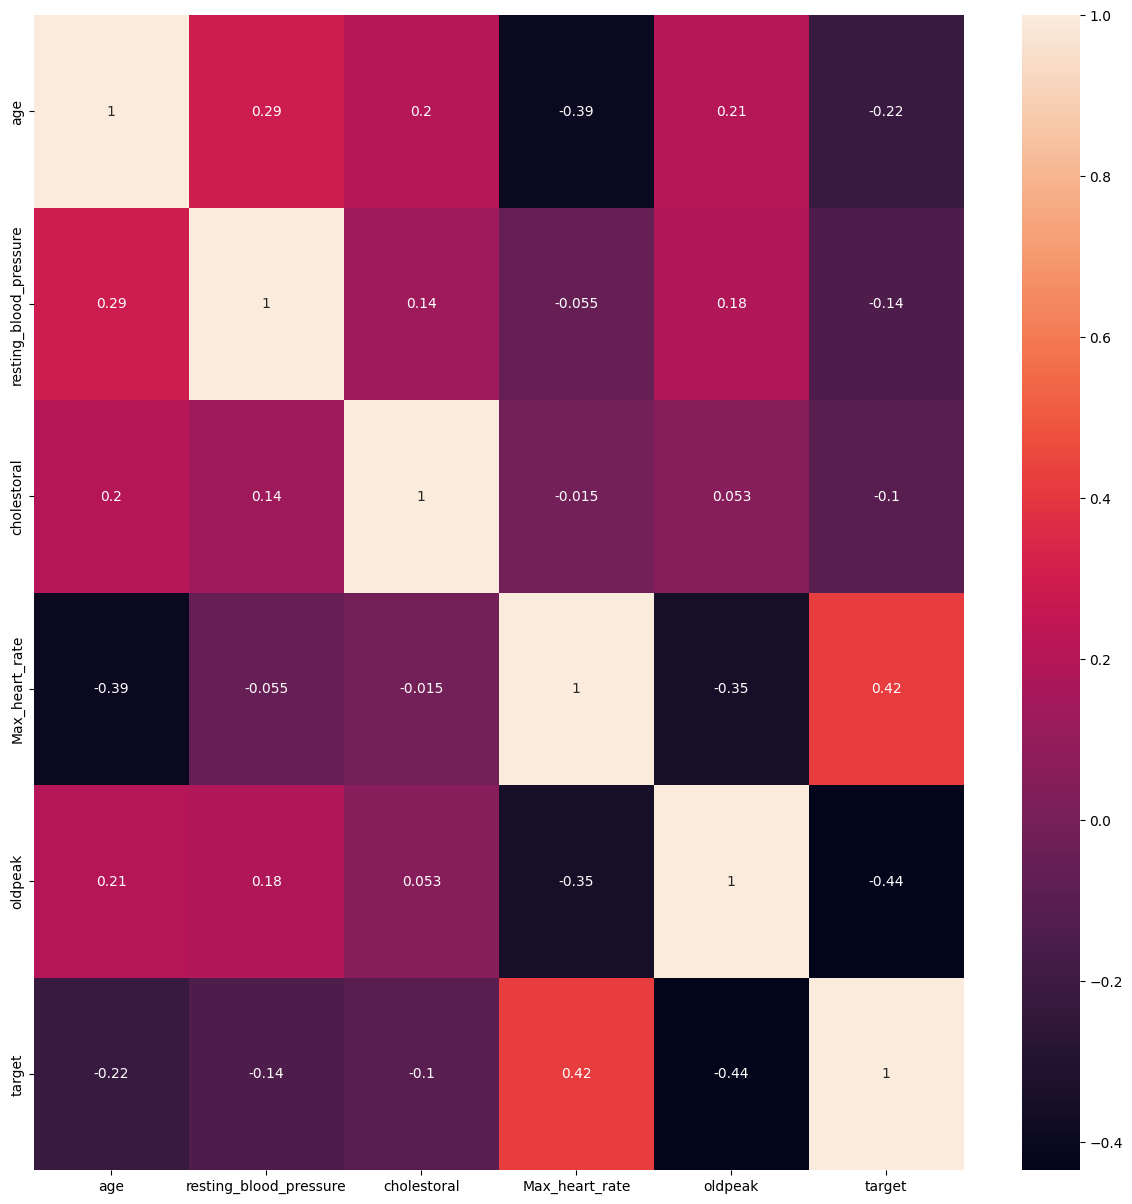

In [46]:
#Heatmap Bivariate analysis
plt.figure(figsize=(15,15))
sns.heatmap(df.select_dtypes(include = 'number').corr(),annot=True)
plt.show()

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            302 non-null    int64  
 1   sex                            302 non-null    object 
 2   chest_pain_type                302 non-null    object 
 3   resting_blood_pressure         302 non-null    float64
 4   cholestoral                    302 non-null    float64
 5   fasting_blood_sugar            302 non-null    object 
 6   rest_ecg                       302 non-null    object 
 7   Max_heart_rate                 302 non-null    float64
 8   exercise_induced_angina        302 non-null    object 
 9   oldpeak                        302 non-null    float64
 10  slope                          302 non-null    object 
 11  vessels_colored_by_flourosopy  302 non-null    object 
 12  thalassemia                    302 non-null    object 


In [48]:
#One hot Encoding columns
columns = ['sex', 'chest_pain_type','fasting_blood_sugar','rest_ecg','exercise_induced_angina','slope','vessels_colored_by_flourosopy','thalassemia']
for i in columns:
  print(df[i].unique())

['Male' 'Female']
['Typical angina' 'Atypical angina' 'Non-anginal pain' 'Asymptomatic']
['Lower than 120 mg/ml' 'Greater than 120 mg/ml']
['ST-T wave abnormality' 'Normal' 'Left ventricular hypertrophy']
['No' 'Yes']
['Downsloping' 'Upsloping' 'Flat']
['Two' 'Zero' 'One' 'Three' 'Four']
['Reversable Defect' 'Fixed Defect' 'Normal' 'No']


In [49]:
#OneHot encoding
df = pd.get_dummies(df, columns = ['sex', 'chest_pain_type','fasting_blood_sugar','rest_ecg','exercise_induced_angina','slope','vessels_colored_by_flourosopy','thalassemia'],drop_first = True, dtype = int)

df.head()


,age,resting_blood_pressure,cholestoral,Max_heart_rate,oldpeak,target,sex_Male,chest_pain_type_Atypical angina,chest_pain_type_Non-anginal pain,chest_pain_type_Typical angina,...,exercise_induced_angina_Yes,slope_Flat,slope_Upsloping,vessels_colored_by_flourosopy_One,vessels_colored_by_flourosopy_Three,vessels_colored_by_flourosopy_Two,vessels_colored_by_flourosopy_Zero,thalassemia_No,thalassemia_Normal,thalassemia_Reversable Defect
0,52,125.0,212.0,168.0,1.0,0,1,0,0,1,...,0,0,0,0,0,1,0,0,0,1
1,53,140.0,203.0,155.0,3.1,0,1,0,0,1,...,1,0,1,0,0,0,1,0,0,1
2,70,145.0,174.0,125.0,2.6,0,1,0,0,1,...,1,0,1,0,0,0,1,0,0,1
3,61,148.0,203.0,161.0,0.0,0,1,0,0,1,...,0,0,0,1,0,0,0,0,0,1
4,62,138.0,294.0,106.0,1.9,0,0,0,0,1,...,0,1,0,0,1,0,0,0,0,0


In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   age                                       302 non-null    int64  
 1   resting_blood_pressure                    302 non-null    float64
 2   cholestoral                               302 non-null    float64
 3   Max_heart_rate                            302 non-null    float64
 4   oldpeak                                   302 non-null    float64
 5   target                                    302 non-null    int64  
 6   sex_Male                                  302 non-null    int64  
 7   chest_pain_type_Atypical angina           302 non-null    int64  
 8   chest_pain_type_Non-anginal pain          302 non-null    int64  
 9   chest_pain_type_Typical angina            302 non-null    int64  
 10  fasting_blood_sugar_Lower than 120 mg/ml  3

In [51]:
#Assigining independent variables to X and target variable to y
X=df.drop('target',axis=1)
y=df['target']

In [52]:
print(X.shape)
print(y.shape)

(302, 22)
(302,)


In [53]:
#Assigning 80% data to testing and 20% to training
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42, stratify=y)

In [54]:
#Importing the model
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [55]:
#Printing result
y_pred = model.predict(X_test)
print(y_pred)

[0 0 0 1 1 0 1 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 1 0 1 0 0 0 0 1 0 1 1 1 0 1 0
 1 1 1 0 1 1 1 0 0 1 0 1 0 0 1 1 0 1 1 0 1 0 0 0]


In [56]:
from sklearn.metrics import accuracy_score
print("Accuracy :", accuracy_score(y_test,y_pred))

Accuracy : 0.8688524590163934


In [57]:
#Generating Classification report
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86        28
           1       0.90      0.85      0.88        33

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



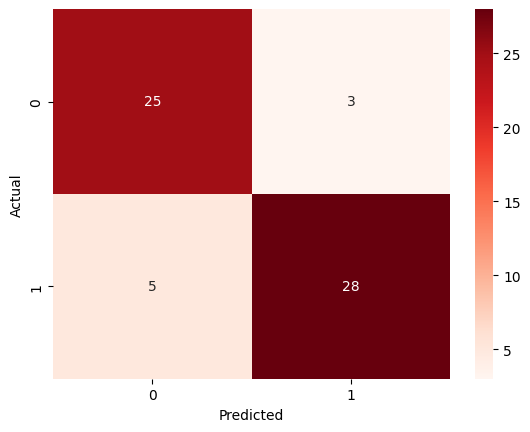

In [58]:
#Generating confusion matrix
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap='Reds')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [59]:
print("training Accuracy: ", model.score(X_train,y_train))
print("testing Accuracy: ", model.score(X_test,y_test))


training Accuracy:  0.8838174273858921
testing Accuracy:  0.8688524590163934
